**Chiara Picarelli**, DCMC - Politecnico di Milano  
chiara.picarelli@polimi.it  
https://github.com/cippee/utils  
November 2025

# Molecular Graph Analysis Notebook

This notebook provides tools to read and analyze molecular graph data stored in H5MD format.  
It includes functions to:
- Load graph frames from an H5MD file
- Define molecule type mappings directly in the notebook
- Inspect the neighbors (contacts) of a specific molecule
- Summarize contacts across all molecules in a frame

The workflow is designed to replace MATLAB scripts with a Pythonic approach using **pandas DataFrames** for tabular data and **NumPy** for numerical operations.

In [36]:
# === Core libraries ===
import h5py         #for reading HDF5/H5MD files
import pandas as pd #for tabular data handling
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns

In [37]:
# Read an H5MD file containing molecular graph data.
def read_graph_h5md(filename):
    graphs_info = []

    # Open the H5MD file in read-only mode
    with h5py.File(filename, "r") as f:
        graphs_group = f["/graphs"]
        nFrames = len(graphs_group.keys())
        print(f"Found {nFrames} frames in file {filename}")

        # Iterate over all frames in the file
        for frame_name in graphs_group.keys():
            frame = graphs_group[frame_name]

            # Read frame attributes
            time = frame["attrs/time"][()]

            # If it's an array, reduce it to a scalar
            if isinstance(time, np.ndarray):
                time = float(time.squeeze())
                
            type_id = frame["vertices/type_id"][()]
            num_vertices = len(type_id)

            # Read edge information
            source = frame["edges/source"][()]
            target = frame["edges/target"][()]
            length_val = frame["edges/length"][()]
            src_atom_id = frame["edges/src_atom_id"][()]
            tgt_atom_id = frame["edges/tgt_atom_id"][()]
            src_label   = frame["edges/src_label"][()].astype(str)
            tgt_label   = frame["edges/tgt_label"][()].astype(str)
            num_edges = len(source)

            # Store all relevant data in a dictionary
            graphs_info.append({
                "time": time,
                "num_vertices": num_vertices,
                "num_edges": num_edges,
                "type_id": type_id,
                "edges_source": source,
                "edges_target": target,
                "edges_length": length_val,
                "edges_src_atom": src_atom_id,
                "edges_tgt_atom": tgt_atom_id,
                "edges_src_label": src_label,
                "edges_tgt_label": tgt_label
            })

            # Print a summary for the current frame
            print(f"\n--- Reading {frame_name} ---")
            print(f"  time = {time:.3f}")
            print(f"  vertices = {num_vertices}")
            print(f"  edges = {num_edges}")
            print(f"  mean distance = {np.mean(length_val):.3f}")
            print(f"  unique type_id = {np.unique(type_id)}")

    print("\nReading completed.")

    return graphs_info

In [38]:
def analyze_contacts_structured(graphs_info, n_molecules, frame_number=1, type_map=None):
    """
    Analyze contacts in a structured manner and return summary and detail DataFrames.
    """
    if type_map is None:
        type_map = {}

    g = graphs_info[frame_number-1]

    source = g["edges_source"]
    target = g["edges_target"]
    distances = g["edges_length"]
    src_atom_id = g["edges_src_atom"]
    tgt_atom_id = g["edges_tgt_atom"]
    src_label   = g["edges_src_label"]
    tgt_label   = g["edges_tgt_label"]
    vertex_type = g["type_id"]

    summary_rows = []
    detail_rows = []

    for mol in range(n_molecules):
        idx_source = source == mol
        idx_target = target == mol
        neighbors = np.concatenate([target[idx_source], source[idx_target]])
        dists = np.concatenate([distances[idx_source], distances[idx_target]])

        if len(neighbors) == 0:
            mol_type_id = int(vertex_type[mol])  # type ID for this molecule
            summary_rows.append({
                "molecule_id": mol,
                "molecule_type": type_map.get(mol_type_id, f"type_{mol_type_id}"),
                "n_contacts": 0,
                "mean_distance": np.nan
            })
            continue

        # Summary row
        mol_type_id = int(vertex_type[mol])
        mol_type = type_map.get(mol_type_id, f"type_{mol_type_id}")
        summary_rows.append({
            "molecule_id": mol,
            "molecule_type": mol_type,
            "n_contacts": len(neighbors),
            "mean_distance": np.mean(dists)
        })

        # Detailed rows
        for j, neigh in enumerate(neighbors):
            neigh_type_id = int(vertex_type[neigh])  # type ID for neighbor
            neigh_type = type_map.get(neigh_type_id, f"type_{neigh_type_id}")
            detail_rows.append({
                "molecule_id": mol,
                "molecule_type": mol_type,
                "neighbor_id": int(neigh),
                "neighbor_type": neigh_type,
                "distance": float(dists[j]),
                "src_atom_id": int(src_atom_id[j]),
                "tgt_atom_id": int(tgt_atom_id[j]),
                "src_label": str(src_label[j]),
                "tgt_label": str(tgt_label[j])
            })

    summary_df = pd.DataFrame(summary_rows)
    detail_df = pd.DataFrame(detail_rows)

    return summary_df, detail_df

In [39]:

# Define type map in a dedicated cell
type_map = {
    0: "CO2",
    1: "H2O"
}

filename = "contacts_frame1.h5"
n_molecules = 5000
frame_number = 1

In [40]:
# Load graph data into a variable
graph_info = read_graph_h5md(filename)

# Now you can analyze
summary_df, detail_df = analyze_contacts_structured(graph_info, n_molecules, frame_number, type_map)

# Summary: one row per molecule
display(summary_df.head())

# Detailed: one row per contact
display(detail_df.head())

Found 1 frames in file contacts_frame1.h5

--- Reading frame_0 ---
  time = 0.000
  vertices = 5000
  edges = 23693
  mean distance = 3.190
  unique type_id = [0 1]

Reading completed.


,molecule_id,molecule_type,n_contacts,mean_distance
0,0,CO2,8,3.192454
1,1,CO2,8,3.230768
2,2,CO2,8,3.243797
3,3,CO2,11,3.281105
4,4,CO2,10,3.285584


,molecule_id,molecule_type,neighbor_id,neighbor_type,distance,src_atom_id,tgt_atom_id,src_label,tgt_label
0,0,CO2,3901,CO2,2.961167,0,1,C,O
1,0,CO2,1586,CO2,3.006616,0,1,C,O
2,0,CO2,1177,CO2,3.053484,0,1,C,O
3,0,CO2,3964,CO2,3.735747,1,0,O,O
4,0,CO2,2517,CO2,3.022232,0,0,C,C


In [47]:
summary_mol4999 = summary_df[summary_df["molecule_id"] == 4999]
display(summary_mol4999)

detail_mol4999 = detail_df[detail_df["molecule_id"] == 4999]
display(detail_mol4999)

,molecule_id,molecule_type,n_contacts,mean_distance
4999,4999,H2O,7,2.944897


,molecule_id,molecule_type,neighbor_id,neighbor_type,distance,src_atom_id,tgt_atom_id,src_label,tgt_label
47379,4999,H2O,2888,CO2,3.243662,0,1,C,O
47380,4999,H2O,4646,H2O,2.702590,0,1,C,O
47381,4999,H2O,829,CO2,2.999825,0,1,C,O
47382,4999,H2O,2134,CO2,3.033697,1,0,O,O
47383,4999,H2O,4227,H2O,2.761799,0,0,C,C
47384,4999,H2O,4557,H2O,2.692508,2,0,O,C
47385,4999,H2O,3046,CO2,3.180198,1,0,O,O


In [54]:
# Trova le molecule_id che hanno solo CO2 come vicini
only_CO2_mols = (
    detail_df
    .groupby("molecule_id")["neighbor_type"]
    .apply(lambda x: (x == "CO2").all())
)

only_CO2_mols = only_CO2_mols[only_CO2_mols].index  # tieni solo quelli True

# Filtra il summary_df
summary_only_CO2 = summary_df[summary_df["molecule_id"].isin(only_CO2_mols)]

display(summary_only_CO2)

detail_mol = detail_df[detail_df["molecule_id"] == 4959]
display(detail_mol)

,molecule_id,molecule_type,n_contacts,mean_distance
0,0,CO2,8,3.192454
1,1,CO2,8,3.230768
4,4,CO2,10,3.285584
5,5,CO2,10,3.168166
7,7,CO2,10,3.228050
...,...,...,...,...
4869,4869,H2O,6,2.920612
4925,4925,H2O,8,3.003743
4930,4930,H2O,8,2.989796
4942,4942,H2O,8,2.903974


,molecule_id,molecule_type,neighbor_id,neighbor_type,distance,src_atom_id,tgt_atom_id,src_label,tgt_label
47111,4959,H2O,2276,CO2,2.970804,0,1,C,O
47112,4959,H2O,1689,CO2,2.759700,0,1,C,O
47113,4959,H2O,659,CO2,3.118945,0,1,C,O
47114,4959,H2O,1468,CO2,2.920031,1,0,O,O
47115,4959,H2O,1557,CO2,2.972100,0,0,C,C
47116,4959,H2O,1325,CO2,3.151535,2,0,O,C


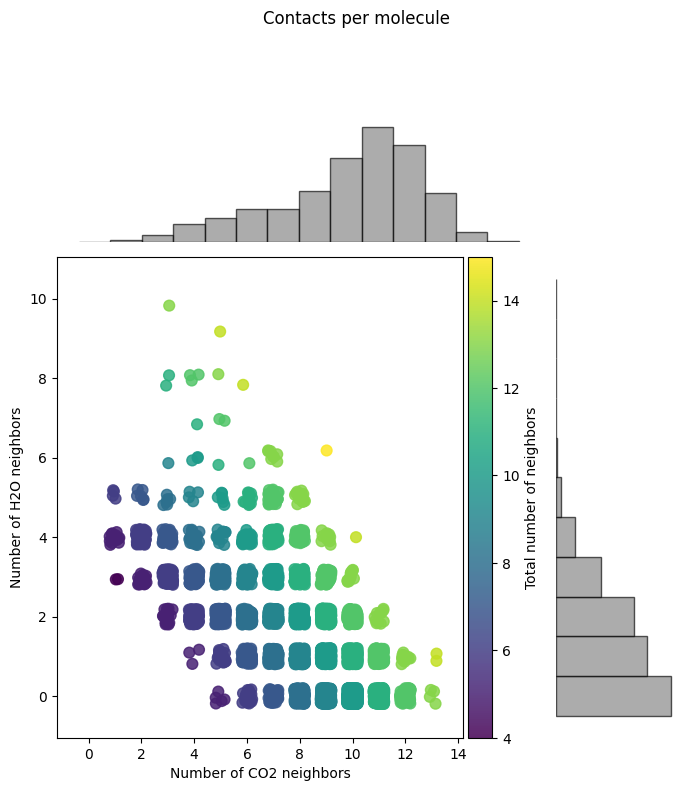

In [ ]:
# Copy detail dataframe
df = detail_df.copy()

# Detect type format (numeric or already string)
if df['neighbor_type'].dtype in [int, float]:
    df['neighbor_type'] = df['neighbor_type'].map(type_map)
else:
    df['neighbor_type'] = df['neighbor_type'].astype(str)

# Dynamic species list
species_list = df['neighbor_type'].unique().tolist()

# Count neighbors per molecola e specie
neighbor_counts = df.groupby(['molecule_id', 'neighbor_type']) \
                    .size().unstack(fill_value=0).reset_index()

# Chck that all species columns exist
for sp in species_list:
    if sp not in neighbor_counts.columns:
        neighbor_counts[sp] = 0

# Total neighbors for colormap
neighbor_counts["total_neighbors"] = neighbor_counts[species_list].sum(axis=1)

# --- Add jitter ---
np.random.seed(42)
for sp in species_list:
    neighbor_counts[f'{sp}_jitter'] = neighbor_counts[sp] + np.random.uniform(-0.2, 0.2, len(neighbor_counts))

# --- Figure layout ---
fig = plt.figure(figsize=(8, 8))
gs = fig.add_gridspec(2, 2, width_ratios=(4, 1), height_ratios=(1, 4),
                      wspace=0.05, hspace=0.05)

ax_scatter = fig.add_subplot(gs[1, 0])
ax_histx   = fig.add_subplot(gs[0, 0], sharex=ax_scatter)
ax_histy   = fig.add_subplot(gs[1, 1], sharey=ax_scatter)

# --- Scatter con colormap continua ---
if len(species_list) >= 2:
    x_species, y_species = species_list[:2]  # the first two species are placed on the axes
else:
    x_species = y_species = species_list[0]

sc = ax_scatter.scatter(
    neighbor_counts[f'{x_species}_jitter'],
    neighbor_counts[f'{y_species}_jitter'],
    c=neighbor_counts['total_neighbors'],
    cmap='viridis',
    s=60,
    alpha=0.85
)

ax_scatter.set_xlabel(f"Number of {x_species} neighbors")
ax_scatter.set_ylabel(f"Number of {y_species} neighbors")

# Colorbar
cbar = plt.colorbar(sc, ax=ax_scatter, pad=0.01)
cbar.set_label("Total number of neighbors")

# --- Function for histograms ---
def safe_bins(values):
    vmax = int(values.max())
    if vmax == 0:
        return np.array([-0.5, 0.5])
    return np.arange(-0.5, vmax + 1.5, 1)

# Dynamic histograms
for axis, sp, horizontal in zip([ax_histx, ax_histy], [x_species, y_species], [False, True]):
    bins = safe_bins(neighbor_counts[sp])
    counts, _ = np.histogram(neighbor_counts[sp], bins=bins)
    if horizontal:
        axis.barh(bins[:-1], counts, height=1, align='edge', alpha=0.65, color="gray", edgecolor="black")
    else:
        axis.bar(bins[:-1], counts, width=1, align='edge', alpha=0.65, color="gray", edgecolor="black")
    axis.axis('off')

plt.suptitle("Contacts per molecule", y=1.02)
plt.show()